Ссылка на clearml с логами обучения: [clearml](https://app.clear.ml/projects/d6209850b8fb417bb10decb4dfaccfd8/tasks/fa3c17a1e8e544fea4628c326a4b5a3e/scalars?columns=selected&columns=type&columns=name&columns=tags&columns=status&columns=project.name&columns=users&columns=started&columns=last_update&columns=last_iteration&columns=parent.name&order=-last_update)

API ключи clearml намеренно удалены

In [1]:
!pip install -q clearml ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 47.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 2.8 MB/s eta 0:00:00


In [ ]:
import os
from clearml import Task
from ultralytics import YOLO
import logging

os.environ["CLEARML_NO_DEFAULT_CONFIG"] = "1"
os.environ["CLEARML_WEB_HOST"] = "https://app.clear.ml"
os.environ["CLEARML_API_HOST"] = "https://api.clear.ml"
os.environ["CLEARML_FILES_HOST"] = "https://files.clear.ml"
os.environ["CLEARML_API_ACCESS_KEY"] = ""
os.environ["CLEARML_API_SECRET_KEY"] = ""

os.environ["CLEARML_NO_DEFAULT_CONFIG"] = "1"

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
task = Task.init(
    project_name="CeramicNet",
    task_name="misha-yolo26s_with_negatives",
    reuse_last_task_id=False
)

params = {
    "model_name": "yolo26s.pt",
    "data_path": "/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/data.yaml",
    "epochs": 50,
    "batch_size": 16,
    "imgsz": 640,
    "optimizer": "auto",
    "lr0": 0.01,
    "close_mosaic": 10,
    "device": 0
}
task.connect(params)

model = YOLO(params["model_name"])

results = model.train(
    data=params["data_path"],
    epochs=params["epochs"],
    batch=params["batch_size"],
    imgsz=params["imgsz"],
    verbose=False,
    optimizer=params["optimizer"],
    lr0=params["lr0"],
    close_mosaic=params["close_mosaic"],
    device=params["device"],
    workers=4,
    plots=True
)

metrics = model.val()

task.close()

ClearML Task: created new task id=fa3c17a1e8e544fea4628c326a4b5a3e


/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


2026-10-22 08:23:59,033 - clearml.Repository Detection - WARNING - Jupyter Notebook auto-logging failed, could not access: /kaggle/working/__notebook_source__.ipynb
ClearML results page: https://app.clear.ml/projects/d6209850b8fb417bb10decb4dfaccfd8/tasks/fa3c17a1e8e544fea4628c326a4b5a3e/output/log
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning:

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.



       2/50      5.31G      1.251      2.893    0.01232          6        640: 100% ━━━━━━━━━━━━ 16/16 4.6it/s 3.5s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.1it/s 0.5s0.8s
                   all         61         51      0.489      0.275      0.308      0.165

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       3/50      5.31G      1.394      2.112    0.01389          6        640: 100% ━━━━━━━━━━━━ 16/16 4.7it/s 3.4s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.1it/s 0.5s0.8s
                   all         61         51      0.609      0.686      0.624      0.316

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
       4/50      5.31G       1.55      1.976    0.01541          6        640: 100% ━━━━━━━━━━━━ 16/16 4.7it/s 3.4s0.2s
                 Class     Images  Instances  

████████████████████████         77% | 15.00/19.37 MB [00:00<00:00, 72.70MB/s]: 

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.0 ms, read: 274.1±77.1 MB/s, size: 151.6 KB)


███████████████████████████████ 100% | 19.37/19.37 MB [00:00<00:00, 31.42MB/s]: 

val: Scanning /kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/labels/val... 61 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 61/61 703.7it/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/labels is not writable, cache not saved.


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.1it/s 1.9s0.7s
                   all         61         51      0.906      0.941      0.972      0.702
Speed: 4.9ms preprocess, 12.2ms inference, 0.0ms loss, 1.7ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-2



0: 640x640 1 kleimo, 9.4ms
1: 640x640 (no detections), 9.4ms
2: 640x640 1 kleimo, 9.4ms
3: 640x640 1 kleimo, 9.4ms
4: 640x640 1 kleimo, 9.4ms
5: 640x640 1 kleimo, 9.4ms
6: 640x640 1 kleimo, 9.4ms
7: 640x640 1 kleimo, 9.4ms
8: 640x640 1 kleimo, 9.4ms
9: 640x640 (no detections), 9.4ms
Speed: 1.9ms preprocess, 9.4ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)


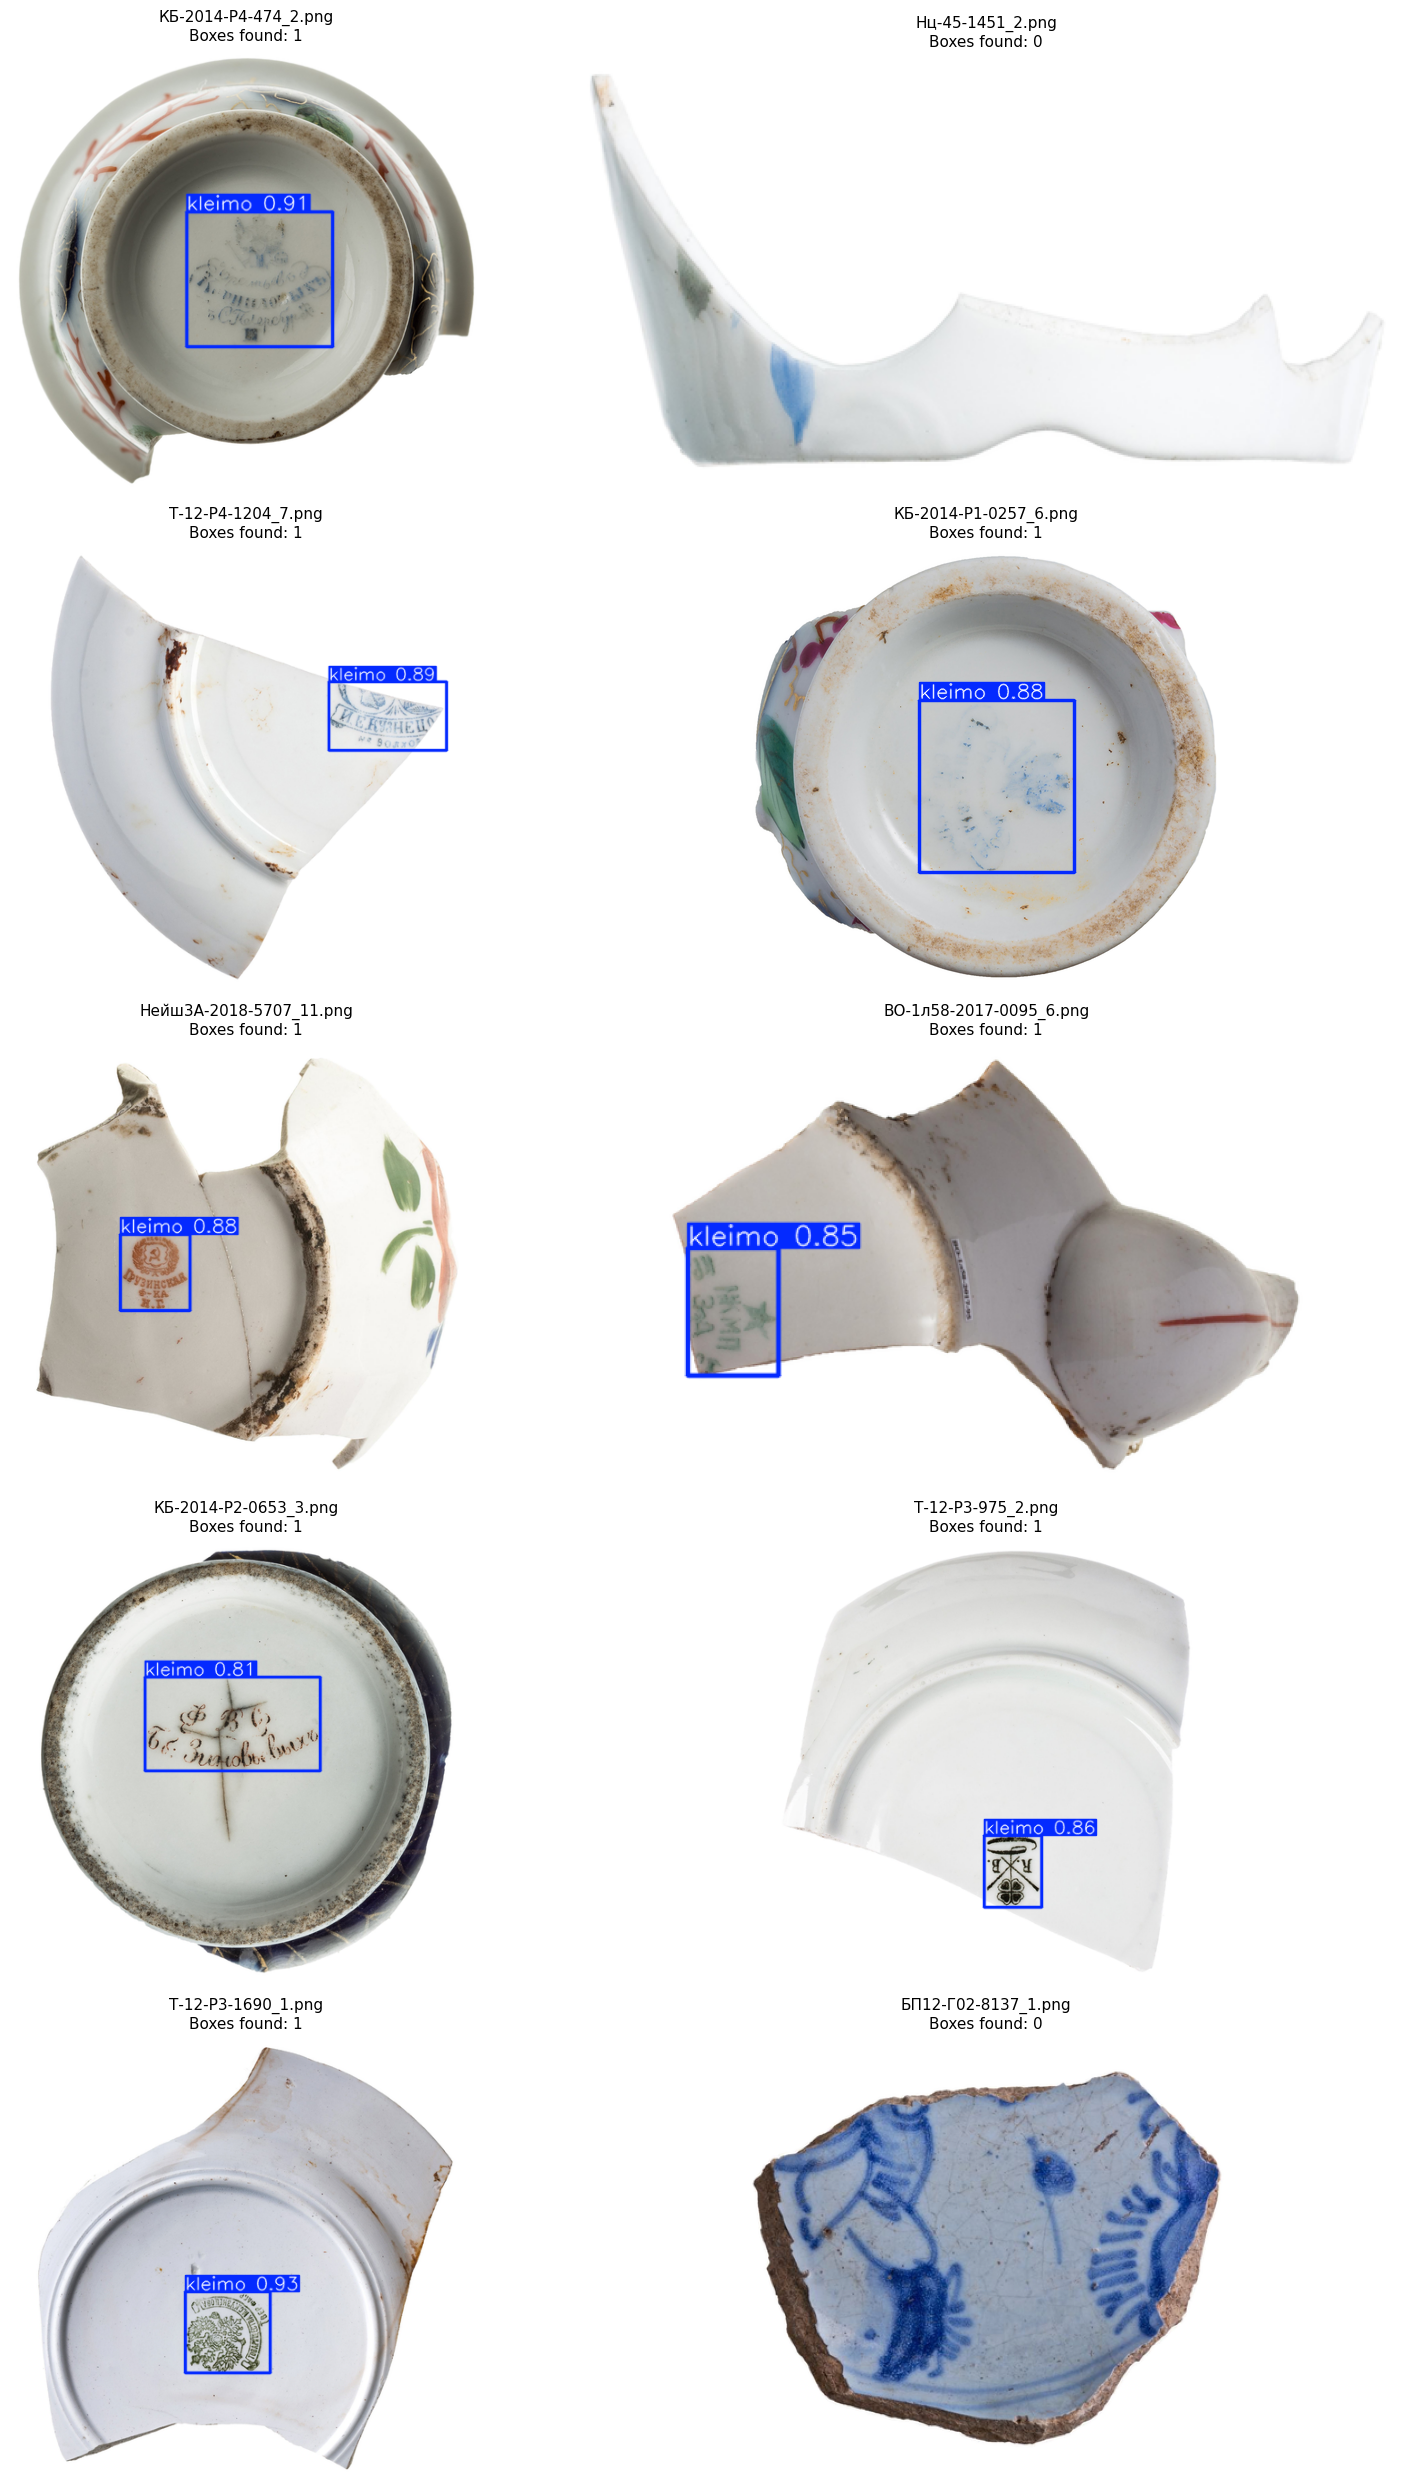

In [4]:
import random
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

val_dir = Path("/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/images/val")
all_val_images = list(val_dir.glob("*.png")) + list(val_dir.glob("*.jpg"))
sample_images = [str(p) for p in random.sample(all_val_images, min(10, len(all_val_images)))]

preds = model.predict(sample_images, conf=0.25, imgsz=640)

fig, axes = plt.subplots(5, 2, figsize=(16, 25))
axes = axes.flatten()

for idx, (img_path, result) in enumerate(zip(sample_images, preds)):
    annotated_img = result.plot()
    annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)
    
    axes[idx].imshow(annotated_img_rgb)
    axes[idx].set_title(f"{Path(img_path).name}\nBoxes found: {len(result.boxes)}", fontsize=11)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

In [10]:
import shutil

exported_path = model.export(format="onnx", imgsz=640, dynamic=False)

onnx_path = "/kaggle/working/ceramic_yolo26s.onnx"
shutil.move(exported_path, onnx_path)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs

PyTorch: starting from '/kaggle/working/runs/detect/train-6/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (19.4 MB)

ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 2.2s, saved as '/kaggle/working/runs/detect/train-6/weights/best.onnx' (36.4 MB)

Export complete (2.8s)
Results saved to /kaggle/working/runs/detect/train-6/weights/best.onnx
Predict:         yolo predict task=detect model=/kaggle/working/runs/detect/train-6/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/kaggle/working/runs/detect/train-6/weights/best.onnx imgsz=640 data=/kaggle/input/datasets/mishasavinov/ceramic-dataset-yolo/ceramic-dataset-yolo/data.yaml 
Visualize:       https://netron.app


'/kaggle/working/ceramic_yolo26s.onnx'